<a href="https://colab.research.google.com/github/Utkxrshaggarwal/Intel-Scene-Classification-CNN/blob/main/intel_image_cnn_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Intel Image Classification with a CNN

Builds a Convolutional Neural Network (TensorFlow/Keras) to classify natural scenes into 6 classes: **buildings, forest, glacier, mountain, sea, street**.

**Before running:** go to `Runtime > Change runtime type > T4 GPU`.

## 1. Setup

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt
import glob, os

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Download the dataset

Uses `kagglehub` to pull the public dataset directly (no manual upload needed).

In [2]:
!pip install -q kagglehub
import kagglehub
path = kagglehub.dataset_download("puneet6060/intel-image-classification")
print("Downloaded to:", path)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Downloaded to: /kaggle/input/intel-image-classification


In [3]:
# Locate train/test folders (the dataset nests them one level deep)
train_dir = os.path.dirname(glob.glob(f"{path}/**/seg_train/**/buildings", recursive=True)[0])
test_dir  = os.path.dirname(glob.glob(f"{path}/**/seg_test/**/buildings",  recursive=True)[0])
print("Train:", train_dir)
print("Test :", test_dir)

Train: /kaggle/input/intel-image-classification/seg_train/seg_train
Test : /kaggle/input/intel-image-classification/seg_test/seg_test


## 3. Load data

In [4]:
IMG_SIZE = (150, 150)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2, subset="training", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH)
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2, subset="validation", seed=42,
    image_size=IMG_SIZE, batch_size=BATCH)
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir, image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)

class_names = train_ds.class_names
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.cache().prefetch(AUTOTUNE)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.
Classes: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


## 4. Look at some images

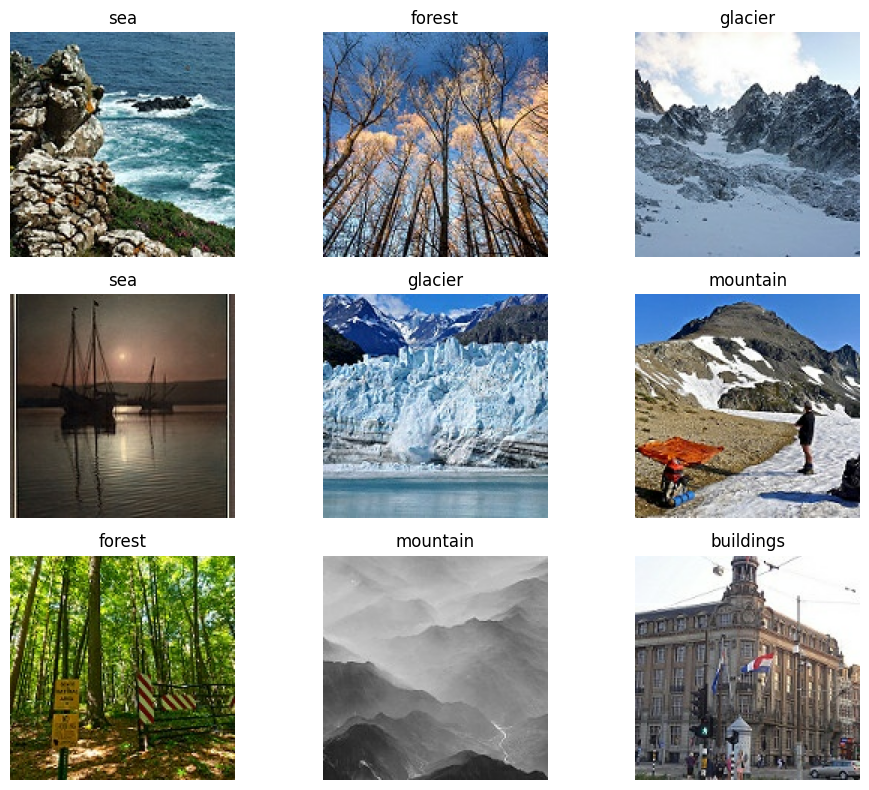

In [5]:
plt.figure(figsize=(10, 8))
for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.show()

## 5. Build the CNN

Three convolution blocks (Conv → BatchNorm → MaxPool), followed by a dense classifier. Data augmentation and dropout reduce overfitting.

In [6]:
data_aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

model = models.Sequential([
    layers.Input(shape=(150, 150, 3)),
    data_aug,
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax"),
])

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 18, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 18, 18, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 9, 9, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 457,670 (1.75 MB)

 Trainable params: 456,710 (1.74 MB)

 Non-trainable params: 960 (3.75 KB)

## 6. Train

In [7]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3),
]

history = model.fit(train_ds, validation_data=val_ds, epochs=30, callbacks=callbacks)

Epoch 1/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 34s 74ms/step - accuracy: 0.5791 - loss: 1.0928 - val_accuracy: 0.4840 - val_loss: 1.4393 - learning_rate: 0.0010
Epoch 2/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 22s 62ms/step - accuracy: 0.7072 - loss: 0.8044 - val_accuracy: 0.7445 - val_loss: 0.6963 - learning_rate: 0.0010
Epoch 3/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 22s 64ms/step - accuracy: 0.7493 - loss: 0.6923 - val_accuracy: 0.6671 - val_loss: 1.0300 - learning_rate: 0.0010
Epoch 4/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 22s 64ms/step - accuracy: 0.7775 - loss: 0.6236 - val_accuracy: 0.7459 - val_loss: 0.6497 - learning_rate: 0.0010
Epoch 5/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 23s 65ms/step - accuracy: 0.7971 - loss: 0.5820 - val_accuracy: 0.6917 - val_loss: 0.8558 - learning_rate: 0.0010
Epoch 6/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 23s 65ms/step - accuracy: 0.8115 - loss: 0.5382 - val_accuracy: 0.6301 - val_loss: 1.1498 - learning_rate: 0.0010
Epoch 7/30
351/351 ━━━━━━━━━━━━━━━━━━━━ 22s 63ms/step - accuracy: 0.8188 - l

## 7. Training curves

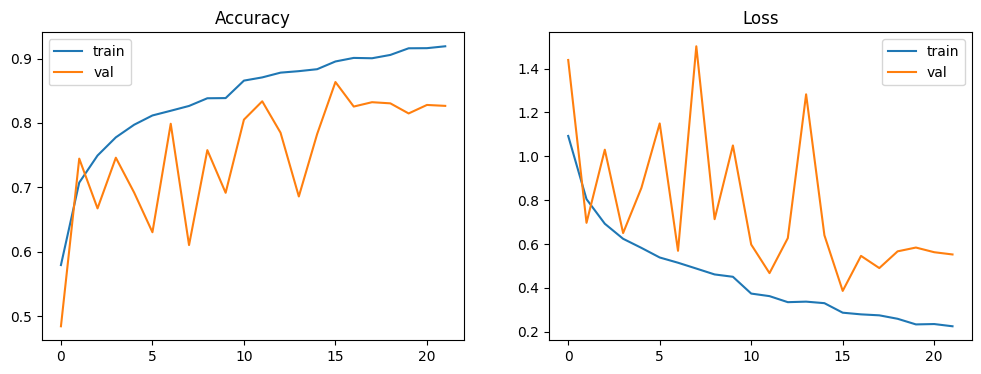

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="val")
ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="val")
ax[1].set_title("Loss"); ax[1].legend()
plt.show()

## 8. Evaluate on the test set

94/94 ━━━━━━━━━━━━━━━━━━━━ 9s 92ms/step - accuracy: 0.8680 - loss: 0.3870
Test accuracy: 0.8680
94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step
              precision    recall  f1-score   support

   buildings       0.75      0.92      0.83       437
      forest       0.99      0.95      0.97       474
     glacier       0.87      0.80      0.83       553
    mountain       0.84      0.82      0.83       525
         sea       0.87      0.91      0.89       510
      street       0.93      0.82      0.87       501

    accuracy                           0.87      3000
   macro avg       0.87      0.87      0.87      3000
weighted avg       0.87      0.87      0.87      3000



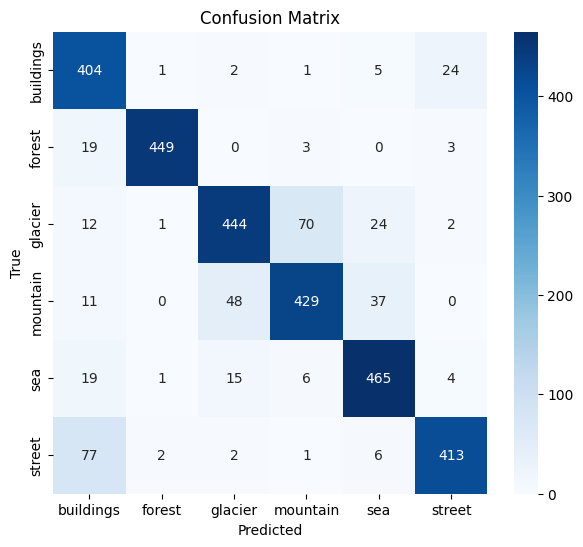

In [9]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

plt.figure(figsize=(7, 6))
sns.heatmap(confusion_matrix(y_true, y_pred), annot=True, fmt="d",
            xticklabels=class_names, yticklabels=class_names, cmap="Blues")
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion Matrix")
plt.show()

## 9. Predict on your own image

Run this cell and upload any photo.

Saving images.jfif to images.jfif
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 266ms/step


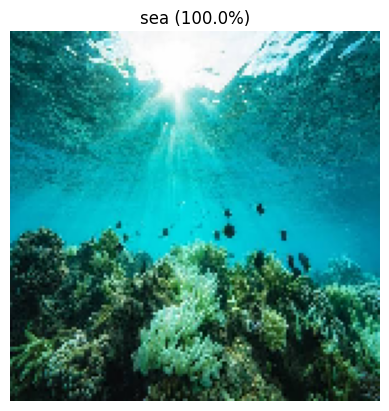

In [10]:
from google.colab import files
from tensorflow.keras.utils import load_img, img_to_array

uploaded = files.upload()
for name in uploaded:
    img = load_img(name, target_size=IMG_SIZE)
    arr = np.expand_dims(img_to_array(img), 0)
    probs = model.predict(arr)[0]
    plt.imshow(img); plt.axis("off")
    plt.title(f"{class_names[np.argmax(probs)]} ({probs.max()*100:.1f}%)")
    plt.show()

## 10. Save the model

In [11]:
model.save("intel_cnn.keras")
files.download("intel_cnn.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
### Next steps to improve accuracy
- Try **transfer learning** (MobileNetV2 / ResNet50) — typically reaches ~92-94% vs ~85-90% for this from-scratch CNN.
- Train longer or tune the learning rate.
- Increase image size to 224x224.